# SAM 3 Full Finetuning  MoNuSAC (multiclass)

The multi-class arm: histopathology with four nucleus types (Epithelial, Lymphocyte, Macrophage, Neutrophil). A fifth label, Ambiguous, has no training examples and appears only in the test set. It is excluded from scoring via ignore_index=5.

Runs at 512px (matches U-Net + the 512 BUSI/Kvasir re-runs). Config: configs/experiment/sam3_full_monusac_full.yaml (finetune_mode: full, num_classes: 5, epochs: 40. MoNuSAC has only 188 train images, so more epochs keep the optimizer-step count comparable to BUSI).

Multiclass eval + qualitative viz adapted from Nik's 02_lora.ipynb. Scoring uses the shared eval_model.py so the numbers line up with 04_unet_predictions.ipynb.


In [2]:
import sys
from pathlib import Path

REPO = "/home/hice1/skang411/group_project"
sys.path.insert(0, f"{REPO}/src")
sys.path.insert(0, f"{REPO}/scripts")

import re
import subprocess

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from eval_model import evaluate
from medseg.data.medseg_data import DataConfig, build_dataloaders
from medseg.engine.metrics import resize_mask, seg_scores
from medseg.models import Sam3MedSeg
from medseg.utils.device import get_device

device = get_device()
print("device:", device)


/storage/ice1/4/1/skang411/envs/sam-medseg/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/storage/ice1/4/1/skang411/envs/sam-medseg/lib/python3.12/site-packages/albumentations/augmentations/pixel/transforms.py:39: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy import special


device: cuda


In [ ]:
MONUSAC_CONFIG = "configs/experiment/sam3_full_monusac_full.yaml"

# Flip True once to submit, then paste the job ID below. Smoke-test first with sam3_full_monusac_smoke.yaml (2 epochs, 8 images) before the 40-epoch run.
SUBMIT_MONUSAC = False

if SUBMIT_MONUSAC:
    out = subprocess.run(
        ["sbatch", "scripts/train_full.sbatch", MONUSAC_CONFIG],
        cwd=REPO, capture_output=True, text=True, check=True,
    )
    print(out.stdout.strip())
else:
    print(f"submission disabled -> sbatch scripts/train_full.sbatch {MONUSAC_CONFIG}")

MONUSAC_JOB_ID = "PASTE_MONUSAC_JOBID"


Submitted batch job 5553011


In [5]:
#!srun --jobid=5553011 nvidia-smi --query-gpu=name --format=csv,noheader
!sacct -j 5553000 --format=JobID,JobName,State,Elapsed,MaxRSS,ReqTRES%40

JobID           JobName      State    Elapsed     MaxRSS                                  ReqTRES 
------------ ---------- ---------- ---------- ---------- ---------------------------------------- 
5553000       sam3_full    RUNNING   00:25:28            billing=8,cpu=8,gres/gpu:h100=1,gres/gp+ 
5553000.bat+      batch    RUNNING   00:25:28                                                     
5553000.ext+     extern    RUNNING   00:25:28                                                     
5553000.0    nvidia-smi  COMPLETED   00:00:00     19608K                                          


## Training curve

In [7]:
epoch_pattern = re.compile(
    r"epoch (\d+): train_loss=([\d.]+)\s+val_dice=([\d.]+)\s+val_nsd=([\d.]+)"
)

log_path = Path(f"{REPO}/slurm_outs/slurm_{MONUSAC_JOB_ID}.out")
if log_path.exists():
    log = log_path.read_text(encoding="utf-8", errors="replace")
    monusac_epochs = pd.DataFrame(
        [
            {"epoch": int(m.group(1)), "train_loss": float(m.group(2)),
             "val_dice": float(m.group(3)), "val_nsd": float(m.group(4))}
            for m in epoch_pattern.finditer(log)
        ]
    )
    display(monusac_epochs)
    if not monusac_epochs.empty:
        ax = monusac_epochs.plot(x="epoch", y=["train_loss", "val_dice", "val_nsd"],
                                 marker="o", figsize=(10, 5))
        ax.set_title("SAM 3 Full Fine-Tuning on MoNuSAC (512px, 5-class)")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Value"); ax.grid(alpha=0.3)
        plt.show()
        best = monusac_epochs.loc[monusac_epochs["val_dice"].idxmax()]
        print(f"best val_dice={best['val_dice']:.4f} @ epoch {int(best['epoch'])}"
              f"   best val_nsd={monusac_epochs['val_nsd'].max():.4f}")
        print("NOTE: in-loop val does NOT apply ignore_index; the reported TEST number below does.")
else:
    print(f"log not found yet: {log_path.name} - job still queued/running?")


log not found yet: slurm_PASTE_MONUSAC_JOBID.out - job still queued/running?


## Test metrics - shared eval_model.py

Same six metrics and evaluator as the UNet and binary SAM arms, so MoNuSAC drops straight into the cross-model table. evaluate auto-sets ignore_index=5 for MoNuSAC (drops the Ambiguous class) and, at 512px output, uses NSD tol=2. normalize=None because the SAM3 arm normalizes internally.

In [4]:
MONUSAC_NC = 5   # trainable classes 0-4; class 5 (Ambiguous) is GT-only, ignored
CKPT_MC = "/storage/ice1/4/1/skang411/checkpoints/sam3_full_monusac_full/best.pt"

model_mc = Sam3MedSeg(finetune_mode="full", num_classes=MONUSAC_NC).to(device).eval()
state = torch.load(CKPT_MC, map_location=device)
model_mc.load_state_dict(state["model"])
print(f"loaded {CKPT_MC}  (epoch {state['epoch']}, val Dice {state['dice']:.4f})")

METRICS = ["precision", "recall", "f1", "iou", "dice", "nsd"]
monusac_results = evaluate(model_mc, "monusac", size=512, normalize=None, splits=("test",))

row = monusac_results["test"]
print(f"\n{'dataset':<10}" + "".join(f"{m:>11}" for m in METRICS))
print("-" * (10 + 11 * len(METRICS)))
print(f"{'monusac':<10}" + "".join(f"{row[m]:>11.4f}" for m in METRICS))
print("\n(macro-averaged over foreground nucleus classes; Ambiguous excluded via ignore_index=5)")


/storage/ice1/4/1/skang411/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/storage/ice1/4/1/skang411/envs/sam-medseg/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


loaded /storage/ice1/4/1/skang411/checkpoints/sam3_full_monusac_full/best.pt  (epoch 14, val Dice 0.7446)

dataset=monusac  scored_at=512  tol=2  ignore_index=5  normalize=None  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
test       101     0.8632     0.7611     0.7922     0.6852     0.7922     0.7137


dataset     precision     recall         f1        iou       dice        nsd
----------------------------------------------------------------------------
monusac        0.8632     0.7611     0.7922     0.6852     0.7922     0.7137

(macro-averaged over foreground nucleus classes; Ambiguous excluded via ignore_index=5)


## Qualitative examples

Sample indices **90, 5, 10, 46, 77** (per Nik) each contains 3-4 nucleus types. test[0:5] are consecutive and, because MoNuSAC is ordered by patient/organ, all show a single nucleus type which makes a multi-class task look binary. The chosen indices are the good multi-class examples. Colours use a colour-vision-deficiency-safe palette; Ambiguous is mid-grey to read as not a prediction target.


monusac TEST: 101 images


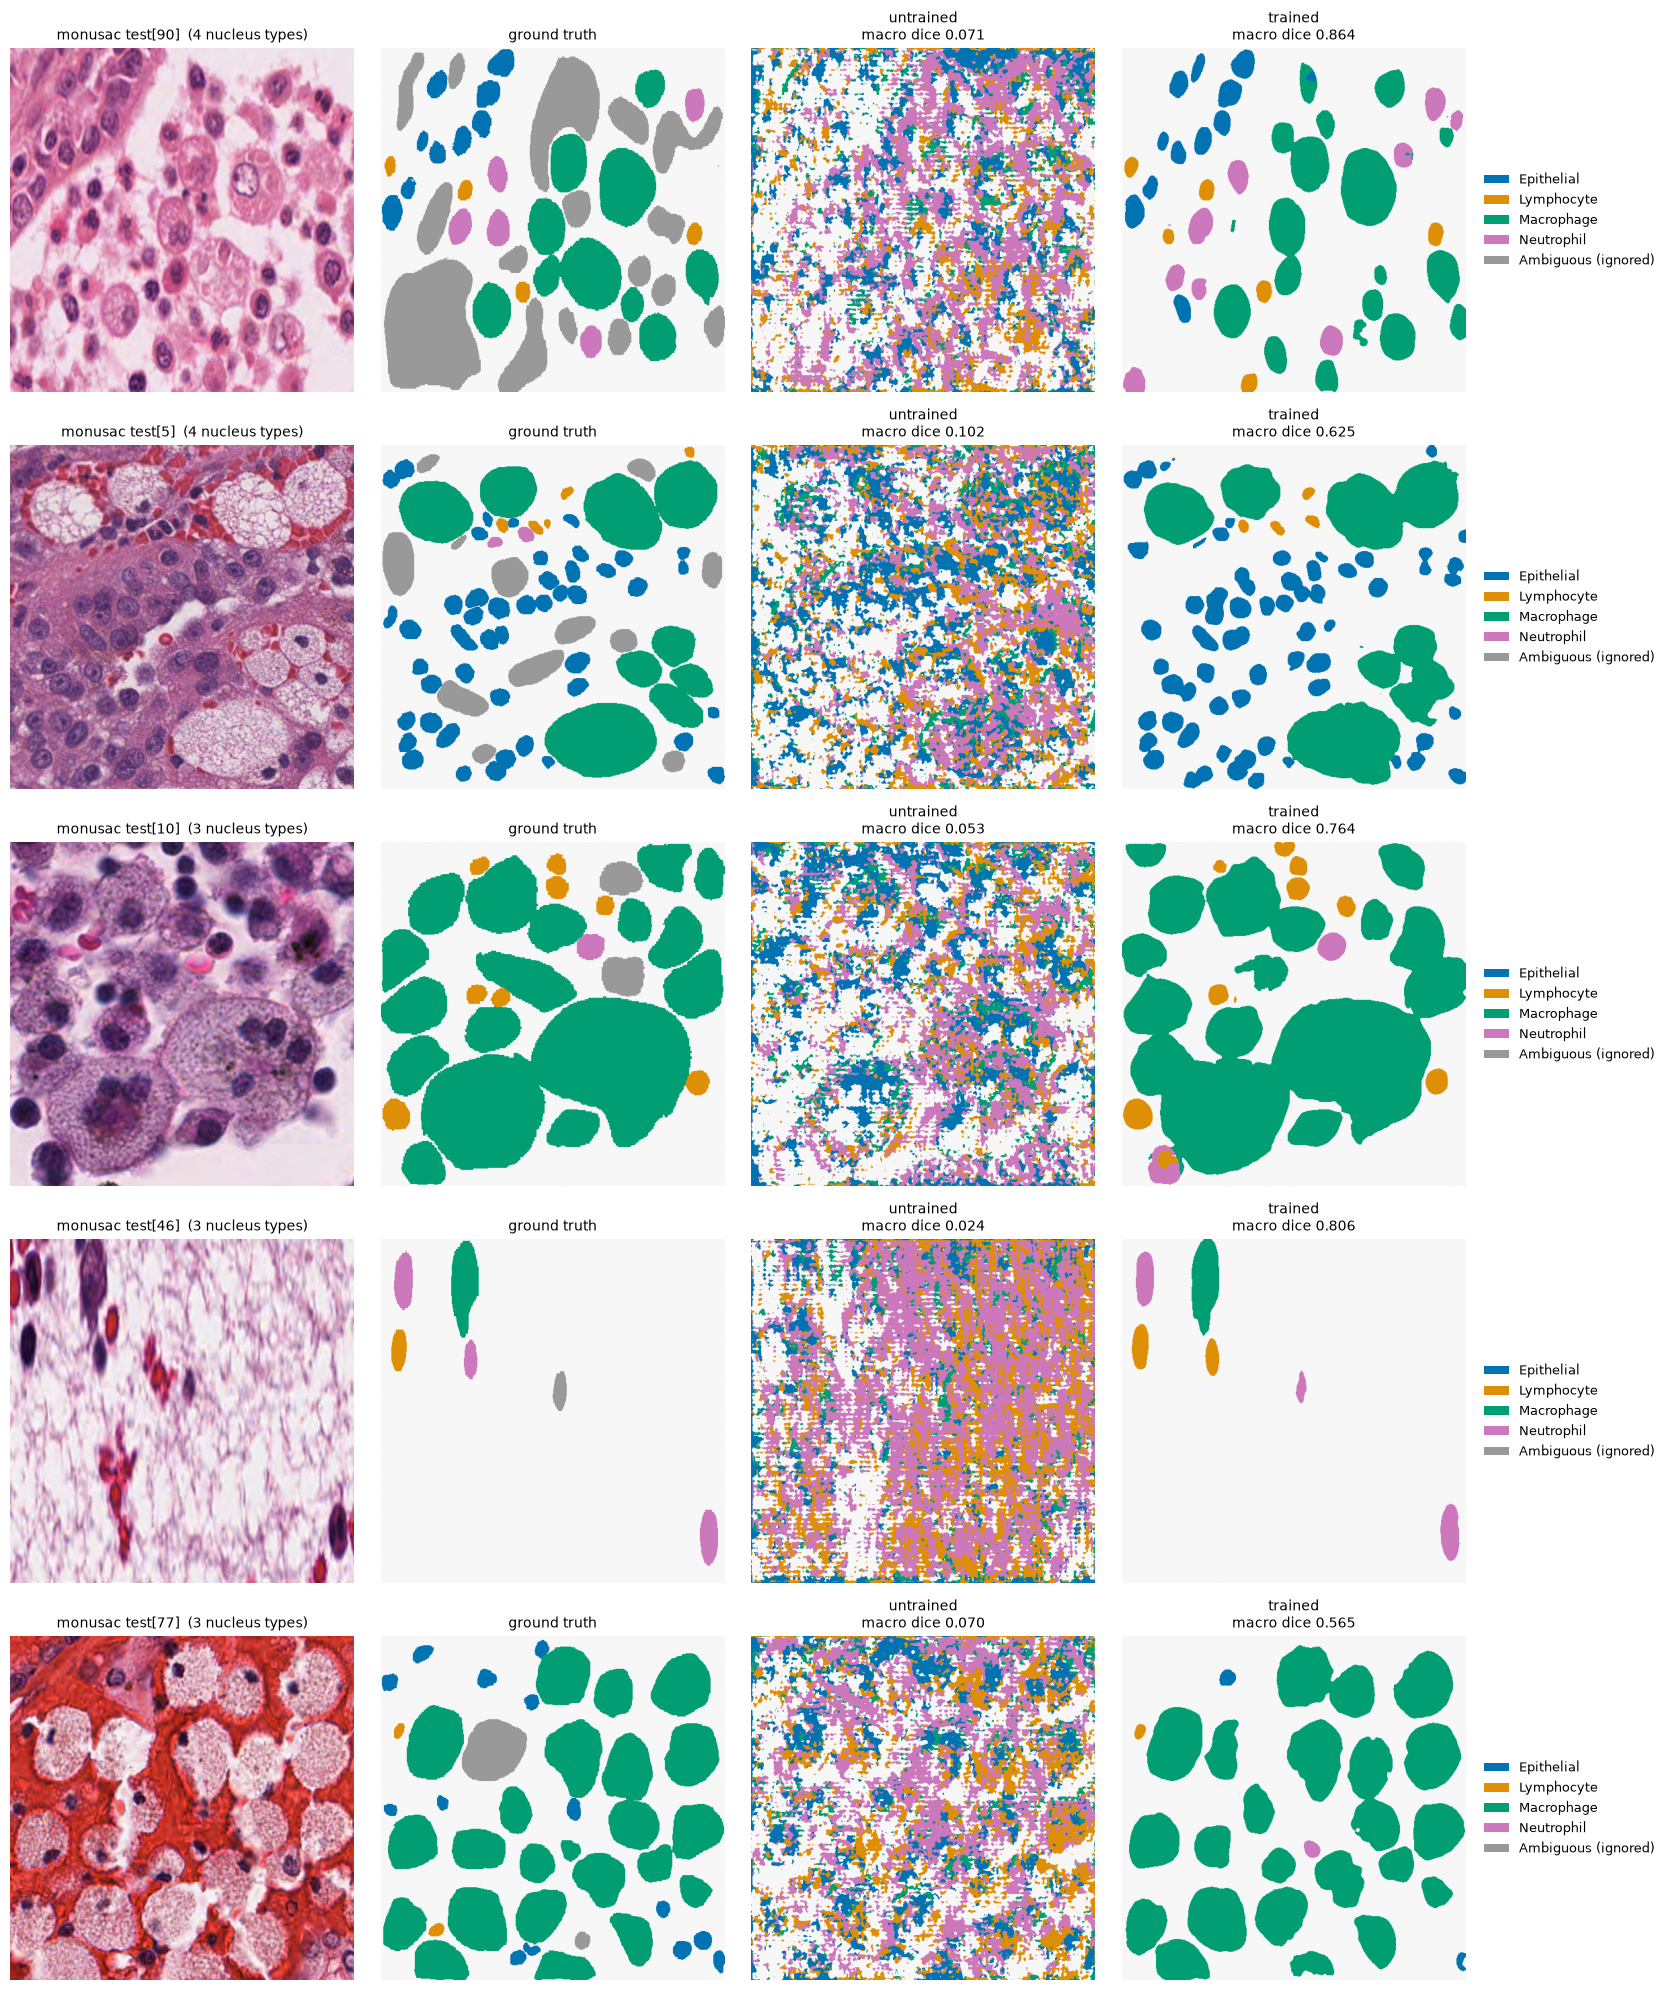

In [5]:
MONUSAC_LABELS = ["background", "Epithelial", "Lymphocyte", "Macrophage", "Neutrophil", "Ambiguous"]
AMBIGUOUS = 5
CLASS_COLORS = ["#f7f7f7", "#0173B2", "#DE8F05", "#029E73", "#CC78BC", "#999999"]
MC_CMAP = ListedColormap(CLASS_COLORS)
MC_NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), MC_CMAP.N)

test_ds_mc = build_dataloaders(
    DataConfig.from_yaml(f"{REPO}/configs/data/monusac.yaml"))["test"].dataset
print(f"monusac TEST: {len(test_ds_mc)} images")


@torch.no_grad()
def predict_labels(model, image):
    """One image -> (H,W) predicted class indices at the image's own resolution."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))
    lab = logits.argmax(1, keepdim=True).float()
    lab = F.interpolate(lab, size=image.shape[-2:], mode="nearest")  # nearest: never invent a class
    return lab[0, 0].cpu().long()


def mc_legend(ax):
    ax.legend(handles=[Patch(facecolor=CLASS_COLORS[c],
                             label=MONUSAC_LABELS[c] + (" (ignored)" if c == AMBIGUOUS else ""))
                       for c in range(1, 6)],
              loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)


def show_monusac(model, baseline, test_ds, indices=(90, 5, 10, 46, 77)):
    """Qualitative panels: input | GT | untrained | trained. 2 forward passes per row."""
    fig, axes = plt.subplots(len(indices), 4, figsize=(17, 4 * len(indices)))
    for r, idx in enumerate(indices):
        s = test_ds[idx]
        img, gt = s["image"], s["mask"]
        img_np = img.permute(1, 2, 0).numpy()
        lab_u, lab_t = predict_labels(baseline, img), predict_labels(model, img)
        d_u = seg_scores(F.one_hot(lab_u, MONUSAC_NC).permute(2, 0, 1)[None].float(),
                         gt[None], tol=2, ignore_index=AMBIGUOUS)[0]
        d_t = seg_scores(F.one_hot(lab_t, MONUSAC_NC).permute(2, 0, 1)[None].float(),
                         gt[None], tol=2, ignore_index=AMBIGUOUS)[0]
        n_cls = len(set(gt.unique().tolist()) - {0, AMBIGUOUS})
        panels = [(img_np, None, f"monusac test[{idx}]  ({n_cls} nucleus types)"),
                  (gt.numpy(), MC_CMAP, "ground truth"),
                  (lab_u.numpy(), MC_CMAP, f"untrained\nmacro dice {d_u:.3f}"),
                  (lab_t.numpy(), MC_CMAP, f"trained\nmacro dice {d_t:.3f}")]
        for col, (data, cm, title) in enumerate(panels):
            ax = axes[r, col]
            ax.imshow(data, cmap=cm, norm=MC_NORM if cm is not None else None)
            ax.set_title(title, fontsize=10); ax.axis("off")
        mc_legend(axes[r, 3])
    plt.tight_layout(); plt.show()


baseline_mc = Sam3MedSeg(finetune_mode="full", num_classes=MONUSAC_NC).to(device)  # untrained reference
show_monusac(model_mc, baseline_mc, test_ds_mc)
